# 4. Repeated measurements

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1 and 3

**Reading:** Taylor, ch. 4, 5.7 and 7 · Bevington & Robinson, ch. 1.3–1.4
and 4.1–4.2 · Fornasini, ch. 7 and 9.2 · Rouaud, ch. I.E · GUM, clause 4.2
and Annex G

The simplest way to learn about random error is to repeat the measurement.
The scatter of the readings tells us how uncertain a single reading is, and
the mean of the readings is a better estimate than any one of them. This
notebook answers four questions.

1. How much better is the mean of $N$ readings than a single reading?
2. How well do we know the uncertainty itself?
3. What changes when $N$ is small?
4. What does averaging *not* cure?

It ends with the weighted mean, used to combine results of different quality.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(3)

## 4.1 Mean, standard deviation and standard error

Let $x_1, \dots, x_N$ be $N$ readings of the same quantity, taken under the
same conditions. Three numbers summarise them.

The **mean** is the best estimate of the quantity,

$$ \bar{x} = \frac{1}{N}\sum_{i=1}^{N} x_i . $$

The **sample standard deviation** measures the scatter of the individual
readings,

$$ s = \sqrt{\frac{1}{N-1}\sum_{i=1}^{N} (x_i - \bar{x})^2 } . $$

It estimates the standard deviation $\sigma$ of the underlying
distribution, and so it is the uncertainty of *one* reading. The divisor is
$N-1$ and not $N$ because the deviations are taken from $\bar x$, which was
itself computed from the same data and therefore lies closer to the
readings than the true value does; one "degree of freedom" has been used.

The **standard error of the mean** is the uncertainty of $\bar{x}$,

$$ u_{\bar{x}} = \frac{s}{\sqrt{N}} . $$

### Where the $\sqrt{N}$ comes from

The mean is a function of the $N$ readings,
$\bar x = \tfrac1N(x_1 + \dots + x_N)$, and we can apply the propagation
law of Chapter 3. Each sensitivity coefficient is
$\partial\bar x/\partial x_i = 1/N$, each reading has the same uncertainty
$\sigma$, and the readings are independent, so

$$ u_{\bar x}^2 = \sum_{i=1}^{N} \left(\frac{1}{N}\right)^{2}\sigma^2 = \frac{\sigma^2}{N} . $$

The standard error is thus not a new concept but the first application of
error propagation. Note where independence was used. If successive
readings are correlated, as successive configurations in a simulation
always are, the cross terms survive and $s/\sqrt{N}$ is too small; see
[Chapter 17](../part4_advanced/17_correlated_data_and_block_averaging.ipynb).

### An example

Ten readings of the time for a ball to roll down a ramp, in seconds:

In [2]:
t = np.array([2.31, 2.27, 2.35, 2.29, 2.33, 2.26, 2.32, 2.30, 2.36, 2.28])

mean, s, sem = ep.mean_sem(t)
print(f"mean               = {mean:.4f} s")
print(f"standard deviation = {s:.4f} s   (uncertainty of one reading)")
print(f"standard error     = {sem:.4f} s   (uncertainty of the mean)")
print("result: t =", ep.format_result(mean, sem, "s"))

mean               = 2.3070 s
standard deviation = 0.0333 s   (uncertainty of one reading)
standard error     = 0.0105 s   (uncertainty of the mean)
result: t = 2.307 ± 0.011 s


## 4.2 Seeing the $1/\sqrt{N}$ law

The claim $u_{\bar x} = \sigma/\sqrt N$ is a statement about what would
happen if the whole experiment, all $N$ readings, were repeated many times:
the means would scatter with standard deviation $\sigma/\sqrt N$. In the
laboratory we rarely have time for that. On a computer we do.

Below, one "experiment" consists of $N$ readings drawn from a normal
distribution with true value 2.30 s and $\sigma = 0.03$ s. We repeat the
experiment 20 000 times for each $N$ and look at the distribution of means.

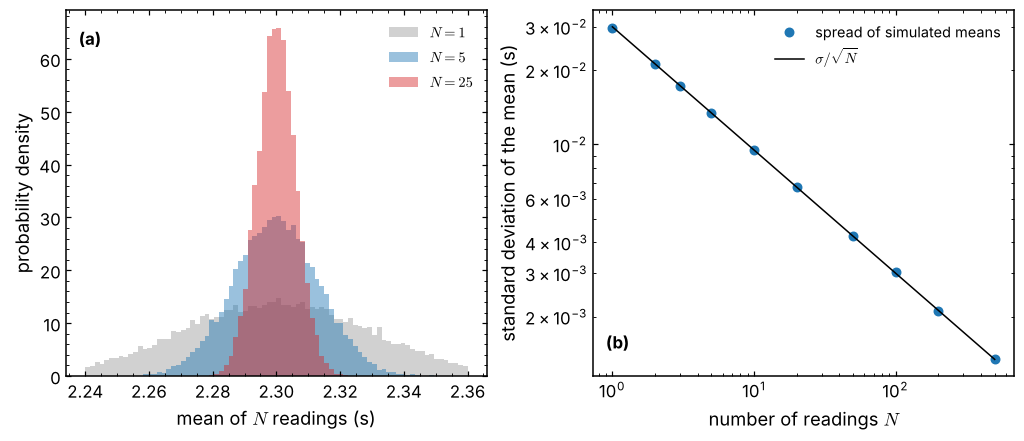

In [3]:
mu, sigma = 2.30, 0.03
n_rep = 20_000

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.9))
ax = axes[0]
bins = np.linspace(mu - 0.06, mu + 0.06, 81)
for N, c in ((1, "0.6"), (5, "C0"), (25, "C3")):
    means = rng.normal(mu, sigma, (n_rep, N)).mean(axis=1)
    ax.hist(means, bins=bins, density=True, histtype="stepfilled", alpha=0.45,
            color=c, label=f"$N={N}$")
ax.set_xlabel("mean of $N$ readings (s)"); ax.set_ylabel("probability density")
ax.legend(); ep.panel_label(ax, "(a)")

ax = axes[1]
Ns = np.array([1, 2, 3, 5, 10, 20, 50, 100, 200, 500])
spread = [rng.normal(mu, sigma, (n_rep, N)).mean(axis=1).std() for N in Ns]
ax.loglog(Ns, spread, "o", color="C0", label="spread of simulated means")
ax.loglog(Ns, sigma / np.sqrt(Ns), "k-", lw=1, label=r"$\sigma/\sqrt{N}$")
ax.set_xlabel("number of readings $N$"); ax.set_ylabel("standard deviation of the mean (s)")
ax.legend(); ep.panel_label(ax, "(b)", x=0.03, y=0.12)
plt.show()

The $1/\sqrt N$ law is a law of diminishing returns. Going from 1 to 4
readings halves the uncertainty; halving it again needs 16 readings, and
again 64. To gain one more significant figure takes a hundred times the
effort. Beyond ten or twenty readings it is usually wiser to improve the
instrument or the method.

## 4.3 The uncertainty of the uncertainty

The standard deviation $s$ is computed from the same $N$ noisy readings,
so it is itself uncertain. For normally distributed readings its relative
standard deviation is, to a good approximation,

$$ \frac{u_s}{s} \approx \frac{1}{\sqrt{2(N-1)}} . $$

| $N$ | 3 | 5 | 10 | 20 | 50 | 200 |
|---|---|---|---|---|---|---|
| $u_s/s$ | 50 % | 35 % | 24 % | 16 % | 10 % | 5 % |

From ten readings the uncertainty is known to about a quarter of its value.
This is the reason for quoting uncertainties to one or two significant
figures and no more.

In [4]:
print("  N   simulated u_s/s   1/sqrt(2(N-1))")
for N in (3, 5, 10, 20, 50, 200):
    s_values = rng.normal(mu, sigma, (n_rep, N)).std(axis=1, ddof=1)
    print(f"{N:4d}      {s_values.std() / s_values.mean():.3f}            {1 / np.sqrt(2 * (N - 1)):.3f}")

  N   simulated u_s/s   1/sqrt(2(N-1))
   3      0.526            0.500
   5      0.362            0.354
  10      0.238            0.236
  20      0.163            0.162
  50      0.102            0.101
 200      0.050            0.050


(The simple formula is slightly off for $N = 3$, where the distribution of
$s$ is noticeably skewed.)

## 4.4 Small samples and Student's $t$

If $\sigma$ were known exactly, the interval $\bar x \pm \sigma/\sqrt N$
would contain the true value in 68.3 % of all experiments. In practice we
use $s$ in place of $\sigma$, and with few readings $s$ is sometimes much
too small. The interval $\bar x \pm s/\sqrt N$ then misses the true value
more often than expected.

The exact correction, for normally distributed readings, is to widen the
interval by a factor $t_{p,\nu}$ taken from Student's $t$ distribution with
$\nu = N-1$ degrees of freedom:

$$ \bar x \pm t_{p,\nu}\,\frac{s}{\sqrt N} . $$

| $N$ | 2 | 3 | 5 | 10 | 20 | $\infty$ |
|---|---|---|---|---|---|---|
| $t$ for 68.3 % | 1.84 | 1.32 | 1.14 | 1.06 | 1.03 | 1.00 |
| $t$ for 95 % | 12.7 | 4.30 | 2.78 | 2.26 | 2.09 | 1.96 |

The simulation below counts how often the interval contains the true value.

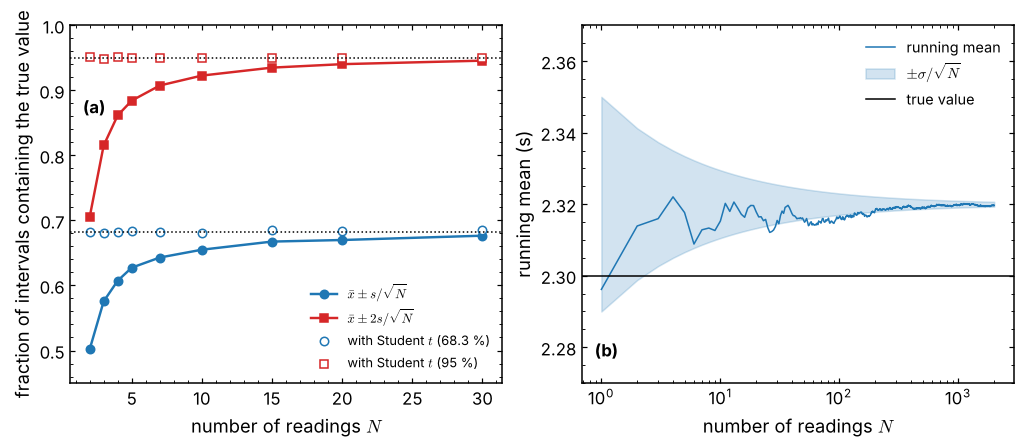

In [5]:
Ns_cov = np.array([2, 3, 4, 5, 7, 10, 15, 20, 30])
cov_plain, cov_t, cov_95_plain, cov_95_t = [], [], [], []
for N in Ns_cov:
    x = rng.normal(mu, sigma, (100_000, N))
    dev = np.abs(x.mean(axis=1) - mu) / (x.std(axis=1, ddof=1) / np.sqrt(N))
    cov_plain.append(np.mean(dev < 1.0))
    cov_t.append(np.mean(dev < stats.t.ppf(0.5 + 0.6827 / 2, N - 1)))
    cov_95_plain.append(np.mean(dev < 2.0))
    cov_95_t.append(np.mean(dev < stats.t.ppf(0.975, N - 1)))

# a systematic offset does not average away
bias = 0.02
N_run = np.arange(1, 2001)
run = np.cumsum(rng.normal(mu + bias, sigma, N_run.size)) / N_run

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.9))
ax = axes[0]
ax.plot(Ns_cov, cov_plain, "o-", color="C0", label=r"$\bar{x}\pm s/\sqrt{N}$")
ax.plot(Ns_cov, cov_95_plain, "s-", color="C3", label=r"$\bar{x}\pm 2s/\sqrt{N}$")
ax.plot(Ns_cov, cov_t, "o", mfc="w", color="C0", label="with Student $t$ (68.3 %)")
ax.plot(Ns_cov, cov_95_t, "s", mfc="w", color="C3", label="with Student $t$ (95 %)")
ax.axhline(0.6827, color="k", ls=":", lw=1); ax.axhline(0.95, color="k", ls=":", lw=1)
ax.set_xlabel("number of readings $N$"); ax.set_ylabel("fraction of intervals containing the true value")
ax.set_ylim(0.45, 1.0); ax.legend(loc="lower right", fontsize=8.5); ep.panel_label(ax, "(a)", y=0.80)

ax = axes[1]
ax.semilogx(N_run, run, "C0", lw=1, label="running mean")
ax.fill_between(N_run, mu + bias - sigma / np.sqrt(N_run), mu + bias + sigma / np.sqrt(N_run),
                color="C0", alpha=0.2, label=r"$\pm\sigma/\sqrt{N}$")
ax.axhline(mu, color="k", lw=1, label="true value")
ax.set_xlabel("number of readings $N$"); ax.set_ylabel("running mean (s)")
ax.set_ylim(2.27, 2.37); ax.legend(loc="upper right"); ep.panel_label(ax, "(b)", y=0.12)
plt.show()

Panel (a): with three readings the plain "$\pm 2$ standard errors" interval
contains the true value only about 82 % of the time instead of 95 %. With
the $t$ factor the coverage is exact (open symbols on the dotted lines).
From about ten readings the difference is small.

## 4.5 What averaging does not cure

Panel (b) shows the running mean of readings from an instrument that reads
0.02 s too long. The shaded band, the standard error, shrinks as $1/\sqrt
N$ and the running mean converges beautifully, to the wrong value. After
2000 readings the standard error is 0.0007 s and the result is wrong by
thirty times that.

The standard error describes random scatter only. A complete uncertainty
adds the Type B contributions of Chapter 1 in quadrature,

$$ u^2 = \underbrace{\frac{s^2}{N}}_{\text{Type A}} + \underbrace{u_\text{resolution}^2 + u_\text{calibration}^2 + \dots}_{\text{Type B}} , $$

and the Type B terms set a floor that no amount of repetition can lower. For
the ramp timings of Section 4.1: the stopwatch displays hundredths of a
second, and suppose its calibration is good to 0.005 s (standard
uncertainty).

In [6]:
u_A = sem
u_res = 0.01 / np.sqrt(12)
u_cal = 0.005
u_total = np.sqrt(u_A**2 + u_res**2 + u_cal**2)
print(f"Type A (standard error)  : {u_A:.4f} s")
print(f"Type B (resolution)      : {u_res:.4f} s")
print(f"Type B (calibration)     : {u_cal:.4f} s")
print(f"combined                 : {u_total:.4f} s")
print("result: t =", ep.format_result(mean, u_total, "s"))

Type A (standard error)  : 0.0105 s
Type B (resolution)      : 0.0029 s
Type B (calibration)     : 0.0050 s
combined                 : 0.0120 s
result: t = 2.307 ± 0.012 s


A related point: if all readings come out identical, $s = 0$, but the
uncertainty is not zero. It only means that the random scatter is smaller
than the resolution of the instrument, and the resolution term takes over.

## 4.6 Combining results of different quality: the weighted mean

Suppose the same quantity has been measured several times with different
methods, giving independent results $x_i \pm u_i$. A plain average would
let a poor result spoil a good one. Instead we look for the linear
combination $\bar x_w = \sum_i a_i x_i$ with $\sum_i a_i = 1$ that has the
smallest variance $\sum_i a_i^2 u_i^2$. Minimising with a Lagrange
multiplier $\lambda$ for the constraint gives $2a_iu_i^2 = \lambda$, that
is, $a_i \propto 1/u_i^2$. With weights $w_i = 1/u_i^2$,

$$ \bar{x}_w = \frac{\sum_i w_i x_i}{\sum_i w_i},
   \qquad u_{\bar{x}_w} = \frac{1}{\sqrt{\sum_i w_i}} . $$

Each result is weighted by the inverse of its variance. For equal
uncertainties this reduces to the ordinary mean and $u/\sqrt N$.

Before combining, check that the results are consistent. The reduced
chi-square $\chi^2_\nu = \frac{1}{N-1}\sum_i w_i (x_i - \bar x_w)^2$ should be
around one. A value much larger than one says that the results disagree by
more than their uncertainties allow, so at least one uncertainty is
underestimated, and the weighted mean should not be trusted as it stands.

In [7]:
# three determinations of a spring constant (N/m) by different methods
k = np.array([24.6, 25.3, 25.05])
u_k = np.array([0.5, 0.4, 0.12])

kw, u_kw, chi2_red = ep.weighted_mean(k, u_k)
print("weighted mean   :", ep.format_result(kw, u_kw, "N/m"), f"   (reduced chi-square {chi2_red:.2f})")
print("unweighted mean :", ep.format_result(*ep.mean_sem(k)[::2], "N/m"))

weighted mean   : 25.05 ± 0.11 N/m    (reduced chi-square 0.60)
unweighted mean : 24.98 ± 0.20 N/m


The weighted mean is close to the most precise result and slightly more
precise than it. The unweighted mean ignores the quoted uncertainties and,
with only three values, rests on a very poorly known standard deviation.

## Summary

* $s$ is the uncertainty of one reading; $s/\sqrt N$ is the uncertainty of
  the mean of $N$ *independent* readings.
* The standard error follows from the propagation law applied to the mean.
* $s$ itself is uncertain by about $1/\sqrt{2(N-1)}$, hence one or two
  significant figures.
* For fewer than about ten readings, widen intervals with Student's $t$.
* Averaging reduces random error only. Systematic and Type B contributions
  remain and must be added in quadrature.
* Results of different quality are combined with weights $1/u_i^2$, after
  checking their consistency.

## Exercises

1. Five readings of a length are 12.31, 12.35, 12.29, 12.34, 12.32 mm. Give
   the mean with its standard uncertainty and with a 95 % interval using
   Student's $t$.
2. You have ten readings and want to halve the standard error. How many more
   readings do you need? What if a Type B contribution equal to the present
   standard error is also present: by how much does the combined uncertainty
   fall?
3. Change the distribution in Section 4.2 from normal to uniform (same
   standard deviation). Does the $1/\sqrt N$ law still hold? Is the
   distribution of the mean for $N = 5$ still close to normal? (This is the
   central limit theorem at work.)
4. Add a fourth result $26.9 \pm 0.3$ N/m to the data of Section 4.6. What
   happens to the reduced chi-square, and what would you do next?

---

**Previous:** [3. Propagation of uncertainty](03_propagation_of_uncertainty.ipynb) &nbsp;·&nbsp; **Next:** [5. Probability distributions and the central limit theorem](../part2_probability_statistics/05_probability_distributions.ipynb)